# Get to Know a Dataset: DE Africa Sentinel-3 Synergy Vegetation

This notebook serves as a guided tour of the [Digital Earth Africa Sentinel-3 Synergy Vegetation](https://registry.opendata.aws/s3_syn_2_vg1]) dataset. More usage examples, tutorials, and documentation for this dataset and others can be found at the [Registry of Open Data on AWS](https://registry.opendata.aws/).



### Dataset Organization & S3 Prefix Structure Overview
***

At the top level of our S3 buckets, we follow a **consistent, product-centric prefix structure** that supports scalable, cloud-native access to **Sentinel-3 SYN Level-2 VG1 stored as Cloud-Optimised GeoTIFFs (COGs)**.

##### Dataset organisation and key S3 prefix structure
1. **Top-level S3 bucket (per product)**

   The variable is stored in its own dedicated S3 bucket, for example:

   * `s3://deafrica-sentinel-3-synergy-vegetation/Sentinel-3/SYN/SY_2_VG1/`

   This separation simplifies data discovery, access management, and scaling as data volumes grow.

2. **Mission prefix**

   ```
   * deafrica-sentinel-3-synergy-vegetation/
   ```

   Identifies the satellite mission and allows future missions to be added without restructuring existing paths.

3. **Instrument prefix**

   ```
   * SYN/
   ```

   Specifies the sensor producing the observations and keeps all products organised consistently.

4. **Processing level and product prefix**

   Each Level-2 product is stored in a dedicated directory, for example:

   * `s3_syn_2_vg1` – Sentinel-3 Level-2 VG1 SYN

   This ensures a clear one-to-one mapping between scientific products and directory paths.

5. **Temporal partitioning**

   Products are partitioned by time using:

   ```
   * YYYY/MM/DD/
   ```

   or, where appropriate:

   ```
   * YYYY/MM/
   ```

   Example:

   ```
   * s3://deafrica-sentinel-3-synergy-vegetation/Sentinel-3/SYN/SY_2_VG1/
   ```

   Temporal partitioning enables efficient S3 prefix filtering and time-based subsetting in cloud workflows.

6. **Cloud-Optimised GeoTIFFs (COGs)**

   Within each temporal directory are individual **Cloud-Optimised GeoTIFF (`.tif`) files**, where:

   * each file represents a single Sentinel-3 Level-2 VG1 SYN
   * internal tiling and overviews enable HTTP range requests
   * files can be streamed directly into GIS tools, xarray/rioxarray, and Dask without full downloads


Full documentation for this dataset can be found at: [https://docs.digitalearthafrica.org/en/latest/sandbox/notebooks/Datasets/Sentinel_3_SYN_VG1.html](https://docs.digitalearthafrica.org/en/latest/sandbox/notebooks/Datasets/Sentinel_3_SYN_VG1.html)

#### Install and import packages

Depending on your environment, you may need to install some packages before importing them. The installation commands in the cell below are effective in Sagemaker Studio Lab (with kernel set to `sagemaker-distribution:Python`) and Google Colab.

If you are running the notebook for the first time, you can remove the `#`s and run the cell below. Often it is more aesthetic to add the `#`s back in after the cell has run because the outputs take a lot of space!

You may see some dependency resolver errors in the output, though this should not affect performance and did not during testing in Colab and SageMaker.

In [1]:
# This notebook requires the following additional libraries
# (Please install using the preferred method for your environment by uncommenting the appropriate lines below):

# !pip install pystac==1.10.0 --force-reinstall
# !pip install odc-stac
# !pip install osmnx
# !pip install pystac_client
# !pip install odc-algo
# !pip install matplotlib
# !pip install -q deafrica-tools
# !pip install -q datacube

In [2]:
# Import the libraries required for this notebook
# Built-ins
import requests
import yaml
import numpy as np
import xarray as xr
import pandas as pd

# Installed libraries
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import odc.algo
from pystac_client import Client
from odc.stac import configure_rio, stac_load
from datacube.utils import masking

### Data Formats, Content Types & Practical Usage Guidance

***

Our dataset is stored using **cloud-native geospatial formats**, chosen to support scalable access, analysis, and visualisation directly from S3 without full file downloads.

#### Data formats present in the dataset

##### 1. Cloud-Optimised GeoTIFF (COG) — `.tif`

**What is stored**

* **Sentinel-3 Level-2 VG1 SYN** 
* Each file represents a **single overpass or temporally aggregated product**
* Raster grids with georeferencing, metadata, and quality information

**Why this format is used**

* Internally tiled with overviews
* Supports HTTP range requests
* Optimised for direct cloud access from S3

**How we work with it**

* Stream directly from S3 using `rasterio`, `rioxarray`, or `xarray`
* Subset spatially and temporally without downloading full files
* Visualise instantly in GIS tools (QGIS, ArcGIS)

**Advice**

* Always treat these as *remote datasets*—avoid downloading unless necessary
* Use windowed reads and bounding boxes for performance
* Prefer `rioxarray.open_rasterio()` or STAC-based loading for analysis



##### 2. STAC metadata (JSON)

**What is stored**

* Collection-level and item-level metadata exposed via the **Digital Earth Africa STAC catalogue**
* Spatial extent, temporal coverage, projection, and asset links pointing to the COGs in S3

**Why this format is used**

* Enables structured discovery and filtering of large datasets
* Decouples metadata from physical storage layout

**How we work with it**

* Query using `pystac_client`
* Filter by bounding box, time range, and product type
* Use STAC assets to access COGs programmatically

**Advice**

* Use STAC as the *entry point* rather than hard-coding S3 paths
* Let STAC handle discovery; let raster tools handle reading

This approach keeps workflows **fast, scalable, and cloud-efficient**, even when working with large time series of Sentinel-3 Level-2 VG1 SYN products.

----

### Downloading and Loading Data from the Dataset

We define the location of our dataset, configure access to AWS S3, and prepare the environment for cloud-native data access

We start by configuring Rasterio/GDAL for unsigned (public) S3 access and explicitly point to the Africa (Cape Town) AWS region, where the data are hosted.
This configuration ensures that Cloud-Optimised GeoTIFFs can be accessed efficiently via HTTP range requests without downloading entire files.

In [3]:
configure_rio(
    cloud_defaults=True,
    aws={"aws_unsigned": True},
    AWS_S3_ENDPOINT="s3.af-south-1.amazonaws.com",
)

Next, we open the Digital Earth Africa STAC catalogue, which provides a structured index over the underlying S3 buckets.
We then define:
1. spatial bounding box (in latitude/longitude),
2. temporal window, and
3. the Sentinel-3 Level-2 VG1 SYN collection to query:

In [4]:
# Open the stac catalogue
catalog = Client.open("https://explorer.digitalearth.africa/stac")

# Set a bounding box
# [xmin, ymin, xmax, ymax] in latitude and longitude
bbox = [24.955, -0.434, 27.955, 2.566]

# Set a start and end date
start_date = '2025-04-13'
end_date =  '2025-04-21'

To load other Sentinel-3 Level-2 VG1 SYN product, the user only needs to change the value inside the collections list. The product is exposed as a separate STAC collection 

The available options are:
 - `s3_syn_2_vg1` to work with the product.
   
To load other Sentinel-3 Level-2 VG1 SYN product, use `s3_syn_2_vg1` in the collections list with the collection corresponding to their variable of interest.

In [5]:
# Set the STAC collections
collections = ["s3_syn_2_vg1"]

The code block below builds and executes a STAC search query using the parameters you defined earlier, then reports how many matching datasets were found.

First, a query is constructed against the Digital Earth Africa STAC catalogue using:
 - the spatial extent (bbox)
 - the selected Sentinel-3 Level-2 VG1 SYN collection(s) (collections)
 - the time range (start_date to end_date)

In [6]:
query = catalog.search(bbox=bbox, collections=collections, datetime=f"{start_date}/{end_date}")

Next, the query is executed and all matching STAC items (each representing an individual dataset, typically a single overpass or time slice) are retrieved:

In [7]:
# Search the STAC catalog for all items matching the query
items = list(query.items())

Finally, the total number of datasets returned by the search is printed:

In [8]:
print(f"Found: {len(items):d} datasets")

Found: 180 datasets


#### Loads the STAC items into an Xarray Dataset

This step **loads the STAC items into an Xarray Dataset** using cloud-native access, converting the Sentinel-3 Level-2 VG1 SYN STAC assets into an analysis-ready data cube.

Here is what each parameter in `stac_load` is doing:

##### Explanation of key parameters

* **`items`**
  The list of STAC items returned from the catalogue search. Each item corresponds to a  Sentinel-3 Level-2 VG1 SYN observation.

* **`crs="EPSG:4326"`**
  Reprojects the data to geographic coordinates (latitude/longitude), making it easy to work with vector boundaries and other global datasets.

* **`chunks={}`**
  Loads the data lazily (Dask-ready) without forcing a specific chunk size. This is appropriate for small time ranges or exploratory analysis.

* **`groupby="solar_day"`**
  Groups individual overpasses by **solar day**, which is particularly important for Sentinel-3 Level-2 VG1 SYN since multiple orbits can occur within a single day.

* **`bbox=bbox`**
  Spatially subsets the data to the defined area of interest, reducing data volume and improving performance.

* **`resolution=0.01`**
  Sets the output spatial resolution (~1000m at the equator). The negative value ensures correct north-up orientation.

In [9]:
ds_S3_syn_2_vg1 = stac_load(
    items,
    crs='EPSG:4326',
    groupby="solar_day",
    bbox=bbox,
    resolution = -0.01,
)

#### Resulting dataset

The output, `ds_S3_syn_2_vg1`, is an **Xarray Dataset** that:

* contains gridded Sentinel-3 Level-2 VG1 SYN
* is spatially and temporally subsetted
* is ready for time-series analysis, mapping, or aggregation
* streams data directly from Cloud-Optimised GeoTIFFs in S3

Displaying `ds_S3_syn_2_vg1` in the notebook allows you to inspect:

* available variables
* spatial dimensions (`x`, `y`)
* temporal dimension (`time` or `solar_day`)
* metadata and coordinate information

This dataset can now be used for visualisation, statistics, or further cloud-scale processing.

In [10]:
# View the Xarray Dataset
ds_S3_syn_2_vg1

<xarray.Dataset> Size: 17MB
Dimensions:       (latitude: 301, longitude: 301, time: 9)
Coordinates:
  * latitude      (latitude) float64 2kB -0.435 -0.425 -0.415 ... 2.555 2.565
  * longitude     (longitude) float64 2kB 27.96 27.95 27.94 ... 24.97 24.96
  * time          (time) datetime64[ns] 72B 2025-04-13 2025-04-14 ... 2025-04-21
    spatial_ref   int32 4B 4326
Data variables: (12/13)
    AG_VG1        (time, latitude, longitude) uint8 815kB 0 0 0 0 0 ... 0 0 0 0
    B0_VG1        (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0
    B2_VG1        (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0
    B3_VG1        (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0
    OG_VG1        (time, latitude, longitude) uint8 815kB 0 0 0 0 0 ... 0 0 0 0
    MIR_VG1       (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0
    ...            ...
    SZA_VG1       (time, latitude, longitude) uint8 815kB 35 35 35 35 ... 0 0 0
    VAA_VG1       (time, latitude, longitude) int16 2MB 102 102 102 ... 0 0 0
    VZA_VG1       (time, latitude, longitude) uint8 815kB 31 32 32 32 ... 0 0 0
    WVG_VG1       (time, latitude, longitude) uint8 815kB 4 4 4 4 4 ... 0 0 0 0
    NDVI_VG1      (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0
    TOA_NDVI_VG1  (time, latitude, longitude) int16 2MB 0 0 0 0 0 ... 0 0 0 0 0

#### Attach product metadata to the loaded dataset

This cell retrieves the Sentinel-3 SYN SY_2_VG1 product definition from Digital Earth Africa and adds its metadata to `ds_S3_syn_2_vg1`. Product-level information is stored in the dataset attributes, while measurement-specific information—including units, nodata values and available flag definitions—is attached to each matching variable.

This updates the metadata without reloading the satellite data.

In [11]:
url = ("https://explorer.digitalearth.africa/products/s3_syn_2_vg1.odc-product.yaml")

response = requests.get(url, timeout=30)
response.raise_for_status()
product = yaml.safe_load(response.text)

# Attach product-level metadata
ds_S3_syn_2_vg1.attrs.update({
    key: value
    for key, value in product.items()
    if key != "measurements"
})

# Attach metadata to every loaded measurement, matching names or aliases
for measurement in product["measurements"]:
    names = [measurement["name"], *measurement.get("aliases", [])]

    for name in names:
        if name in ds_S3_syn_2_vg1.data_vars:
            ds_S3_syn_2_vg1[name].attrs.update(measurement)

#### Applying Scale Factors and Offsets to Sentinel-3 SYN SY_2_VG1 Measurements

> **⚠️ Note:** Some Sentinel-3 SYN (SY_2_VG1) measurements are stored as integers with a **scale factor** (e.g., **0.0001**) or an **offset** (e.g., **1000**) applied. This approach reduces storage requirements while preserving precision. To obtain the correct physical values, the scale factor and/or offset must be reversed during processing.
>
> The example below demonstrates how to apply this correction. In this dataset, several Sentinel-3 measurements use a scale factor of **10,000**, as shown in the output of the **List Measurements** section above. You can recover the original values by either dividing by **10,000**, multiplying by **0.0001**, or, more generally, by retrieving the scale factor from the measurement attributes using `.attrs.get("scale_factor")`, as demonstrated in the example below.

#### Visualise Sentinel-3 SYN SY_2_VG1 `NDVI_VG1` band

The cell below visualizes the NDVI from surface reflectance at the time of observation.

**Without applying the *scale factor*, pay close attention to the units.**

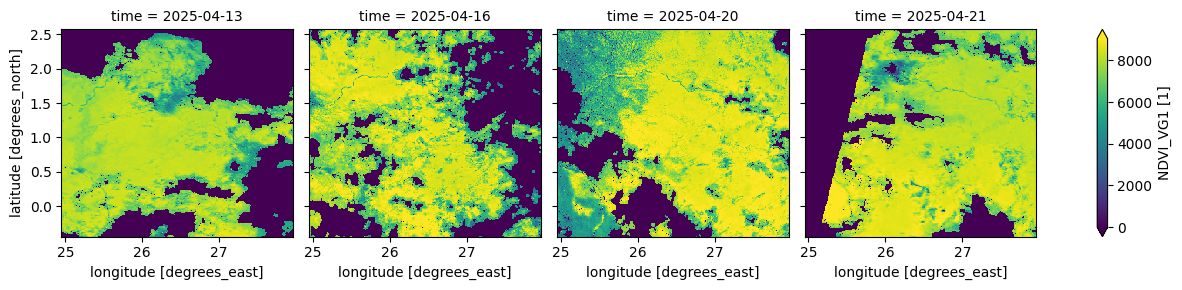

In [12]:
(ds_S3_syn_2_vg1['NDVI_VG1'].isel(time=[0, 3, -2, -1])).plot(robust=True, col="time", col_wrap=4);

**After applying the *scale factor*, pay close attention to the units.**

In [13]:
# Retrieve scale factor using the .attrs.get('scale_factor') measurement attribute
scale_factor = ds_S3_syn_2_vg1['NDVI_VG1'].attrs.get('scale_factor')

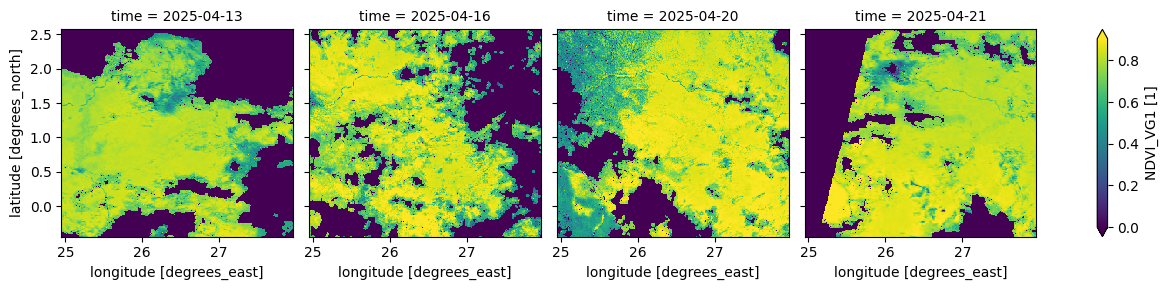

In [14]:
(ds_S3_syn_2_vg1['NDVI_VG1'].isel(time=[0, 3, -2, -1])*scale_factor).plot(robust=True, col="time", col_wrap=4);

Before using any measurement band, always check whether a scale factor or offset needs to be applied before using the data for further analysis. After confirming this, the same process described above can be used to visualize all the other measurement bands available for the product.

#### What this visual shows

* Each panel represents **NDVI_VG1**, gridded over the area of interest.
* The use of `col="time"` creates a **small-multiples view**, making it easy to compare spatial patterns from day to day.


#### Why this is informative

* You can immediately see **hotspots and gradients** across space.
* Day-to-day differences highlight **temporal variability**, which may be linked to:
* Masked (blank) areas clearly show where **quality filtering** has removed invalid pixels, reinforcing confidence in the data.

#### Why this should excite users

* This is **satellite data streamed directly from the cloud**, not pre-downloaded files.
* With just a few lines of code, users can:

  * visualise total_suspended_matter over any region
  * build time series
* The same workflow scales seamlessly from **two days** to **multiple years** of observations.

#### Takeaway

This visual demonstrates that the dataset is:

* **analysis-ready**
* **spatially rich**
* **temporally dense**
* and perfectly suited for **exploratory science, policy analysis, and storytelling**


## Understanding BOA and TOA NDVI

The Sentinel-3 SYN SY_2_VG1 product provides both BOA/surface NDVI (`NDVI_VG1`) and Top-of-Atmosphere NDVI (`TOA_NDVI_VG1`). BOA NDVI represents surface-level vegetation conditions after atmospheric correction, while TOA NDVI is calculated before full atmospheric correction and still includes atmospheric effects such as aerosols, water vapour, and clouds.

Comparing BOA NDVI and TOA NDVI helps users understand how atmospheric correction affects the NDVI values. In this notebook, `NDVI_VG1` is used as the main vegetation layer for analysis, while `TOA_NDVI_VG1` is included as a supporting layer to help users understand the difference between surface-corrected and atmosphere-influenced NDVI.

Most Sentinel-3 products include a **dataMask** or quality layer that helps users remove pixels affected by invalid observations, cloud, missing data, or other quality issues. However, because a readily available **dataMask** is not available for **Sentinel-3 SYN SY_2_VG1**, we need to apply a simple quality-masking approach ourselves by removing unreliable values, such as **0 NDVI values** and invalid reflectance pixels, before producing maps, plots, and time-series analysis. The steps below provide the necessary guidance for applying quality masking. Users can choose the method that best suits your analysis and data requirements.

### Applying the scale factor

In [15]:
ds_S3_syn_2_vg1_scaled = ds_S3_syn_2_vg1*scale_factor

The cell below extracts the surface/BOA NDVI layer (`NDVI_VG1`) and the Top-of-Atmosphere NDVI layer (`TOA_NDVI_VG1`) from the scaled Sentinel-3 SYN SY_2_VG1 dataset. It then calculates and prints the minimum and maximum values for each NDVI layer while ignoring missing values. This step helps confirm that the NDVI values are within the expected range of -1 to 1 and supports the quality-checking process before plotting or further analysis.

In [16]:
boa_ndvi = ds_S3_syn_2_vg1_scaled["NDVI_VG1"]
toa_ndvi = ds_S3_syn_2_vg1_scaled["TOA_NDVI_VG1"]

print("BOA NDVI min:", float(boa_ndvi.min(skipna=True)))
print("BOA NDVI max:", float(boa_ndvi.max(skipna=True)))
print("TOA NDVI min:", float(toa_ndvi.min(skipna=True)))
print("TOA NDVI max:", float(toa_ndvi.max(skipna=True)))

BOA NDVI min: -0.08
BOA NDVI max: 0.92
TOA NDVI min: -0.08
TOA NDVI max: 0.908


This code identifies pixels where BOA NDVI_VG1 is equal to 0 and calculates how common these 0 values are for each observation date. It counts the total number of valid pixels, the number of zero-value NDVI pixels, and the percentage of valid pixels affected by 0 values. This summary helps assess whether 0 NDVI values are isolated or widespread, and supports the decision on whether they should be masked before plotting and time-series analysis.

In [17]:
zero_mask = boa_ndvi == 0

zero_count = zero_mask.sum(dim=["latitude", "longitude"])
valid_count = boa_ndvi.notnull().sum(dim=["latitude", "longitude"])
zero_percent = (zero_count / valid_count) * 100

zero_summary = pd.DataFrame({
    "time": boa_ndvi.time.values,
    "valid_pixels": valid_count.values,
    "zero_ndvi_pixels": zero_count.values,
    "zero_ndvi_percent": zero_percent.values,
})

zero_summary

,time,valid_pixels,zero_ndvi_pixels,zero_ndvi_percent
0,2025-04-13,90601,31889,35.197183
1,2025-04-14,90601,90601,100.000000
2,2025-04-15,90601,90601,100.000000
3,2025-04-16,90601,26389,29.126610
4,2025-04-17,90601,86660,95.650158
5,2025-04-18,90601,90601,100.000000
6,2025-04-19,90601,90601,100.000000
7,2025-04-20,90601,13121,14.482180
8,2025-04-21,90601,24140,26.644298


The next cells identifies observation dates where more than 10% of the valid BOA NDVI_VG1 pixels have values equal to 0. These dates are important because a high percentage of 0 NDVI values may indicate poor-quality observations, missing data, failed retrievals, or cloud-affected pixels. By identifying these dates, users can decide whether to mask the affected pixels, remove poor-quality dates, or investigate them further before producing NDVI plots and time-series analysis.

In [18]:
high_zero_dates = zero_summary[zero_summary["zero_ndvi_percent"] > 10]
high_zero_dates

,time,valid_pixels,zero_ndvi_pixels,zero_ndvi_percent
0,2025-04-13,90601,31889,35.197183
1,2025-04-14,90601,90601,100.000000
2,2025-04-15,90601,90601,100.000000
3,2025-04-16,90601,26389,29.126610
4,2025-04-17,90601,86660,95.650158
5,2025-04-18,90601,90601,100.000000
6,2025-04-19,90601,90601,100.000000
7,2025-04-20,90601,13121,14.482180
8,2025-04-21,90601,24140,26.644298


### Quality Masking for Reliable NDVI Analysis

Most Sentinel-3 products include a dataMask or quality layer that helps users remove pixels affected by invalid observations, cloud, missing data, or other quality issues. However, because a readily available dataMask is not exposed for Sentinel-3 SYN SY_2_VG1 in our current workflow, we apply a simple quality-masking approach ourselves by removing unreliable values, such as 0 NDVI values and invalid reflectance pixels, before producing maps, plots, and time-series analysis.

This code removes 0 values from the BOA NDVI_VG1 layer and compares the original NDVI image with the masked NDVI image. The purpose is to assess whether 0 values are influencing the visual interpretation of vegetation condition. In the masked image, pixels with NDVI equal to 0 are treated as no-data, allowing users to see the vegetation pattern without potentially unreliable low-value pixels affecting the plot.

In [19]:
#keeps only pixels where boa_ndvi value is not equal to 0.
boa_ndvi_masked_zero = boa_ndvi.where(boa_ndvi != 0)

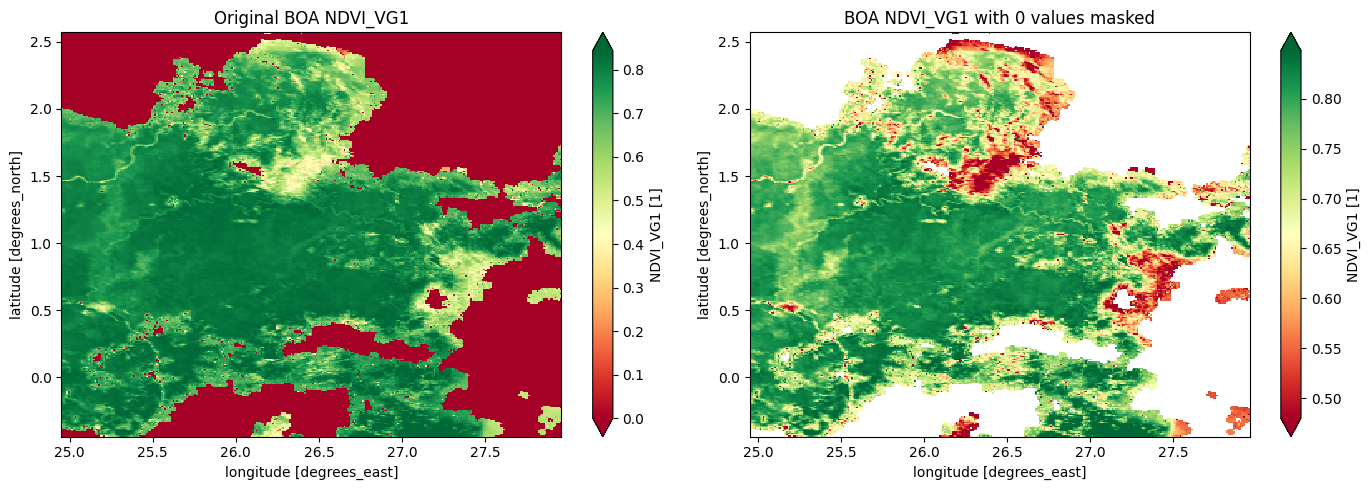

In [20]:
#selects the first time step
time_index = 0

#plot the original against the masked data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#original 
boa_ndvi.isel(time=time_index).plot(
    ax=axes[0],
    robust=True,
    cmap="RdYlGn"
)
axes[0].set_title("Original BOA NDVI_VG1")

#masked
boa_ndvi_masked_zero.isel(time=time_index).plot(
    ax=axes[1],
    robust=True,
    cmap="RdYlGn"
)
axes[1].set_title("BOA NDVI_VG1 with 0 values masked")

plt.tight_layout()
plt.show()

### Compare BOA NDVI VG1 with TOA NDVI VG1

This code compares TOA_NDVI_VG1 and BOA NDVI_VG1 for a selected observation date using a scatter plot. Each point represents one pixel, with TOA NDVI shown on the x-axis and BOA NDVI shown on the y-axis. We can see that the BOA values are generally higher than TOA values for the same acquisition as values are to the top-left of the 1:1 line. This is because atmospheric corrections remove the effect of aerosols, haze, or other interference and lead to a higher, 'cleaner', NDVI value.

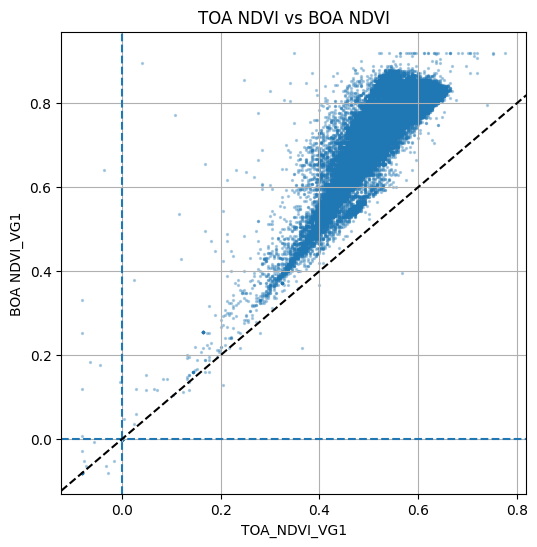

In [21]:
# Select the first time step for the comparison
time_index = 0

boa_flat = boa_ndvi.isel(time=time_index).values.flatten()
toa_flat = toa_ndvi.isel(time=time_index).values.flatten()

valid = np.isfinite(boa_flat) & np.isfinite(toa_flat)

plt.figure(figsize=(6, 6))
plt.scatter(toa_flat[valid], boa_flat[valid], s=2, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")
plt.axline((0, 0), slope=1, color="black", linestyle="--", label="1:1 Line")
plt.xlabel("TOA_NDVI_VG1")
plt.ylabel("BOA NDVI_VG1")
plt.title("TOA NDVI vs BOA NDVI")
plt.grid(True)
plt.show()

### Limitations and next steps

*Where do seasonal NDVI patterns recur in Sentinel-3 VG1 data, and how do they relate to land use, climate variability, and human activity ?*

**Why these data are suitable:**
Sentinel-3 SYN_VG1 provides near-daily, continental-scale coverage, making it possible to detect recurring spatial patterns and seasonal signals that are difficult to observe with sparse ground measurements.

**Recommendations for answering this question:**

* Analyse **multi-year time series** rather than short windows to separate seasonal cycles from noise.
* Apply **strict quality and cloud filtering** before any aggregation.
* Use **consistent spatial grids and temporal grouping** (e.g. solar day or monthly composites).
* Validate patterns where possible using inventories or independent observations.

This approach allows users to move from short-term exploration to **robust, policy-relevant insights**.

## Additional information

<b> License </b> The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0).

Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

<b> Contact </b> If you need assistance, please post a question on the [DE Africa Slack channel](https://digitalearthafrica.slack.com/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).

If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).